# 1차시 (교사용) | CSV 데이터 분석으로 살펴보는 경북 시·군의 인구 구조

**SW·AI 교과융합 수업: 지방소멸위험 데이터 기반의 K-means 군집 분석 PBL**

### 학습목표
- CSV 파일을 pandas로 불러와 데이터의 구조를 파악하고, 고령인구비율과 지방소멸위험지수를 계산할 수 있다.
- 산점도를 활용하여 지역별 인구 구조의 차이를 시각화하고, 지역 간 인구 불균형 문제를 해석할 수 있다.

### 데이터
`gyeongbuk_2025.csv` : 경상북도 22개 시·군(22행 × 5열)

| 열 이름 | 의미 |
|---|---|
| 시군 | 시·군 이름 |
| 연도 | 기준 연도(2025) |
| 총인구 | 전체 인구(명) |
| 청년여성인구 | 20~39세 여성 인구(명) |
| 고령인구 | 65세 이상 인구(명) |

> 자료: 한국고용정보원(KEIS) 지방소멸위험지수 데이터(2025년)를 수업용으로 가공
> 지방소멸위험지수 = 20~39세 여성 인구 ÷ 65세 이상 인구 (0.5 미만이면 소멸위험지역)

**사용 방법:** 위에서부터 차례대로 셀을 실행하세요(Shift + Enter). `___` 부분은 빈칸입니다.

## 0. 준비하기

In [1]:
# ① 데이터가 있는 깃허브 저장소('계정명/저장소명') ※ 교사가 처음 한 번만 수정
REPO = '계정명/저장소명'
BASE = f'https://raw.githubusercontent.com/{REPO}/main/data/'
# ② 그래프에서 한글이 보이도록 패키지 설치
!pip install -q koreanize-matplotlib

## 활동2. pandas로 CSV 파일 불러오기
깃허브에 올려 둔 CSV 파일을 인터넷 주소(URL)로 바로 불러옵니다(0번 셀의 `BASE` 사용).

In [2]:
import pandas as pd  # pandas 라이브러리
DATA_URL = BASE + 'gyeongbuk_2025.csv'
df = pd.read_csv(DATA_URL)
print(df.head())     # 앞의 5개 행 확인
print(df.shape)      # (행의 개수, 열의 개수)
print(df.columns)    # 열 이름 확인

    시군    연도     총인구  청년여성인구    고령인구
0  포항시  2025  489898   43210  113636
1  경주시  2025  244411   19484   68848
2  김천시  2025  134925   10821   38014
3  안동시  2025  153754   13661   44724
4  구미시  2025  403974   45119   54966
(22, 5)
Index(['시군', '연도', '총인구', '청년여성인구', '고령인구'], dtype='str')


## 활동3. 데이터 탐색하기
열 선택, 정렬, 조건 검색으로 데이터를 살펴봅시다.

In [3]:
# 하나의 열 선택
print(df['총인구'])
# 여러 열 선택
print(df[['시군', '총인구']])
# 평균, 표준편차, 최솟값, 최댓값 등 요약
print(df.describe())
# 총인구가 많은 3개 시·군
top3 = df.sort_values('총인구', ascending=False)
print(top3.head(3))
# 조건으로 행 선택하기
print(df[df['시군'] == '포항시'])

0     489898
1     244411
2     134925
3     153754
4     403974
5      98042
6      96797
7      90996
8      66259
9     265622
10     48325
11     23552
12     15231
13     32958
14     40286
15     29874
16     41029
17    105895
18     54117
19     28508
20     45999
21      9022
Name: 총인구, dtype: int64
     시군     총인구
0   포항시  489898
1   경주시  244411
2   김천시  134925
3   안동시  153754
4   구미시  403974
5   영주시   98042
6   영천시   96797
7   상주시   90996
8   문경시   66259
9   경산시  265622
10  의성군   48325
11  청송군   23552
12  영양군   15231
13  영덕군   32958
14  청도군   40286
15  고령군   29874
16  성주군   41029
17  칠곡군  105895
18  예천군   54117
19  봉화군   28508
20  울진군   45999
21  울릉군    9022
           연도            총인구        청년여성인구           고령인구
count    22.0      22.000000     22.000000      22.000000
mean   2025.0  114521.545455   9621.090909   30613.727273
std       0.0  127989.892107  13185.579002   25343.960244
min    2025.0    9022.000000    518.000000    2772.000000
25%    2025.0   34790.000000   1

## 활동4. 새로운 지표 계산하기
- 고령인구비율(%) = 고령인구 ÷ 총인구 × 100
- 지방소멸위험지수 = 청년여성인구 ÷ 고령인구
- 같은 행(시·군)의 값끼리 한 번에 계산됩니다(행렬의 원소별 연산과 같은 원리).

In [4]:
# 고령인구비율(%) = 고령인구 ÷ 총인구 × 100
df['고령인구비율'] = df['고령인구'] / df['총인구'] * 100
# 소멸위험지수 = 청년여성인구 ÷ 고령인구
df['소멸위험지수'] = df['청년여성인구'] / df['고령인구']
# 지수가 0.5 미만이면 소멸위험지역(True)
df['소멸위험'] = df['소멸위험지수'] < 0.5
cols = ['시군', '고령인구비율', '소멸위험지수', '소멸위험']
print(df[cols].round(2))
n = df['소멸위험'].sum()
print(f"소멸위험지역 수: {n}개 / {len(df)}개")

     시군  고령인구비율  소멸위험지수   소멸위험
0   포항시   23.20    0.38   True
1   경주시   28.17    0.28   True
2   김천시   28.17    0.28   True
3   안동시   29.09    0.31   True
4   구미시   13.61    0.82  False
5   영주시   32.60    0.21   True
6   영천시   34.60    0.19   True
7   상주시   37.43    0.16   True
8   문경시   36.88    0.17   True
9   경산시   21.28    0.52  False
10  의성군   48.44    0.09   True
11  청송군   44.50    0.10   True
12  영양군   43.48    0.11   True
13  영덕군   44.24    0.10   True
14  청도군   45.21    0.10   True
15  고령군   38.87    0.14   True
16  성주군   39.98    0.12   True
17  칠곡군   21.10    0.37   True
18  예천군   34.18    0.20   True
19  봉화군   44.51    0.09   True
20  울진군   33.08    0.20   True
21  울릉군   30.72    0.19   True
소멸위험지역 수: 20개 / 22개


## 활동5. 산점도로 시각화하기
x좌표는 총인구, y좌표는 고령인구비율 → 각 시·군은 좌표평면 위의 한 점 (x, y)입니다.

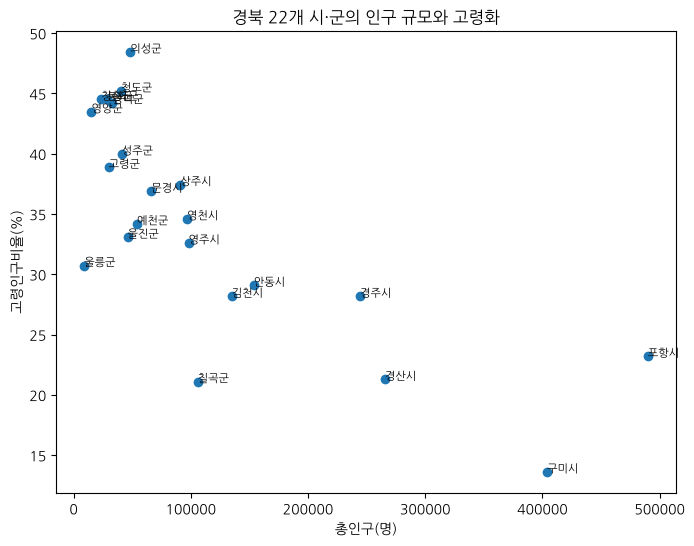

In [5]:
import matplotlib.pyplot as plt
import koreanize_matplotlib
plt.figure(figsize=(8, 6))
plt.scatter(df['총인구'], df['고령인구비율'])
# 각 점에 시·군 이름 표시
for i in range(len(df)):
    x, y = df['총인구'][i], df['고령인구비율'][i]
    plt.text(x, y, df['시군'][i], fontsize=8)
plt.xlabel('총인구(명)')
plt.ylabel('고령인구비율(%)')
plt.title('경북 22개 시·군의 인구 규모와 고령화')
plt.show()

## 활동6. 지역의 인구 구조 해석하기
소멸위험지역을 색으로 구분하고, 시(市)와 군(郡)의 평균을 비교해봅시다.

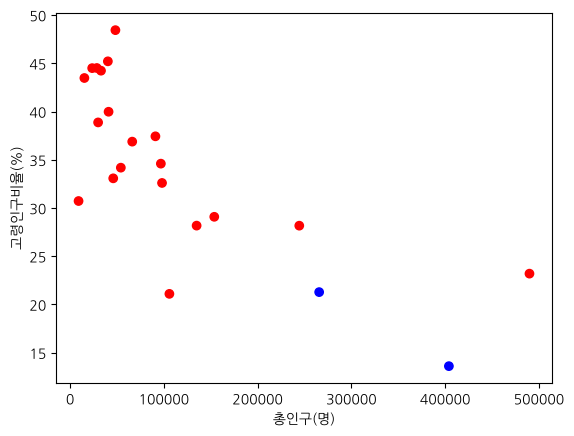

          총인구  고령인구비율  소멸위험지수
구분                           
군    39566.33   39.03    0.15
시   204467.80   28.50    0.33


In [6]:
# 소멸위험지역은 빨간색, 아닌 지역은 파란색
c = df['소멸위험'].map({True: 'red', False: 'blue'})
plt.scatter(df['총인구'], df['고령인구비율'], c=c)
plt.xlabel('총인구(명)')
plt.ylabel('고령인구비율(%)')
plt.show()
# 시(市)와 군(郡)의 평균 비교
# 이름의 마지막 글자: '시' 또는 '군'
df['구분'] = df['시군'].str[-1]
cols = ['총인구', '고령인구비율', '소멸위험지수']
print(df.groupby('구분')[cols].mean().round(2))

## 모둠활동지 1 | 경북 시·군 인구 구조 분석 시스템

In [7]:
import pandas as pd
DATA_URL = BASE + 'gyeongbuk_2025.csv'
df = pd.read_csv(DATA_URL)
print("=== 경북 시·군 인구 구조 분석 시스템 ===\n")
# 1. 지표 계산
df['고령인구비율'] = df['고령인구'] / df['총인구'] * 100
df['소멸위험지수'] = df['청년여성인구'] / df['고령인구']
# 2. 경북 전체 평균
print(f"평균 총인구: {df['총인구'].mean():,.0f}명")
print(f"평균 고령인구비율: {df['고령인구비율'].mean():.2f}%")
# 3. 고령인구비율 상위 5개 시·군
top5 = df.sort_values('고령인구비율', ascending=False).head(5)
print("\n고령인구비율 상위 5개 시·군:")
names, rates = top5['시군'], top5['고령인구비율']
for i, (name, rate) in enumerate(zip(names, rates), 1):
    print(f"{i}위 {name}: {rate:.2f}%")
# 4. 소멸위험지역 분류 (지수 0.5 미만)
risk = df[df['소멸위험지수'] < 0.5]
safe = df[df['소멸위험지수'] >= 0.5]
print(f"\n소멸위험지역: {len(risk)}개 / {len(df)}개")
print("소멸위험지역이 아닌 시·군:", list(safe['시군']))
# 5. 총인구와 고령인구비율의 상관계수 (-1 ~ 1)
r = df['총인구'].corr(df['고령인구비율'])
print(f"\n총인구와 고령인구비율의 상관계수: {r:.2f}")
# 6. 우리 지역(포항시)의 위치
pohang = df[df['시군'] == '포항시'].iloc[0]
rank = (df['소멸위험지수'] > pohang['소멸위험지수']).sum() + 1
print(f"\n포항시 소멸위험지수: {pohang['소멸위험지수']:.2f}")
print(f"포항시 순위(지수 높은 순): {rank}위 / {len(df)}개")

=== 경북 시·군 인구 구조 분석 시스템 ===

평균 총인구: 114,522명
평균 고령인구비율: 34.24%

고령인구비율 상위 5개 시·군:
1위 의성군: 48.44%
2위 청도군: 45.21%
3위 봉화군: 44.51%
4위 청송군: 44.50%
5위 영덕군: 44.24%

소멸위험지역: 20개 / 22개
소멸위험지역이 아닌 시·군: ['구미시', '경산시']

총인구와 고령인구비율의 상관계수: -0.76

포항시 소멸위험지수: 0.38
포항시 순위(지수 높은 순): 3위 / 22개


## 모둠활동지 2 | 생각 정리하기

**Q1.** df['고령인구'] / df['총인구'] * 100 한 줄로 22개 시·군의 고령인구비율을 한 번에 계산할 수 있었던 이유를 써봅시다.

> **모범답안** pandas에서 열(Series)끼리 연산하면 같은 행(시·군)에 있는 값끼리 원소별로 계산됩니다. 공통수학1에서 배운 행렬의 덧셈·실수배가 같은 위치의 원소끼리 계산되는 것과 같은 원리이므로, 반복문을 쓰지 않아도 22개 시·군의 값을 한 번에 계산할 수 있습니다. 예를 들어 포항시는 113,636 ÷ 489,898 × 100 ≈ 23.20(%)로 계산됩니다.

**Q2.** 산점도와 상관계수에서 총인구와 고령인구비율 사이에 어떤 경향이 나타나는지 쓰고, 그 이유를 통합사회에서 배운 산업화·도시화와 인구 이동의 관점에서 설명해봅시다.

> **모범답안** 총인구가 적은 시·군일수록 고령인구비율이 높은 경향이 나타납니다. 상관계수는 약 -0.76(-1에 가까울수록 반대 방향 경향이 강함)이며, 시(市) 지역의 평균 고령인구비율은 28.50%, 군(郡) 지역은 39.03%입니다. 산업화·도시화 과정에서 일자리와 교육·의료 시설이 도시에 집중되면서 청년층이 도시나 수도권으로 이동하고, 농촌 지역에는 고령층의 비율이 높아진 결과로 해석할 수 있습니다.

**Q3.** 포항시의 소멸위험지수와 순위를 확인하고, 우리 지역의 인구 문제를 해결하기 위한 방안을 제안해봅시다.

> **모범답안** 포항시의 소멸위험지수는 약 0.38로 0.5 미만이므로 소멸위험지역에 해당하며, 경북 22개 시·군 중 구미시(0.82), 경산시(0.52)에 이어 3번째로 높습니다. 경북에서 인구가 가장 많은 포항시도 소멸위험지역에 해당한다는 점에서 경북 전체의 인구 문제가 심각함을 알 수 있습니다. 해결 방안으로는 청년 일자리 확대, 청년·신혼부부 주거 지원, 보육 시설 확충, 문화·생활 기반 시설 개선 등을 제안할 수 있습니다.(모둠별 자유 응답)